<a href="https://colab.research.google.com/github/Dhilip-24/DL/blob/main/language_identification1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Load and Preprocess the Dataset
We will begin by loading `/content/dataset.csv`, handling any missing values, and examining the distribution of languages.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/dataset.csv')

# Display basic information and the first few rows
print("Dataset Shape:", df.shape)
print("\nDataset Columns and Types:")
display(df.info())
print("\nFirst 5 rows:")
display(df.head())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset Shape: (22000, 2)

Dataset Columns and Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Text      22000 non-null  object
 1   language  22000 non-null  object
dtypes: object(2)
memory usage: 343.9+ KB


None


First 5 rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Missing values per column:
Text        0
language    0
dtype: int64


In [2]:
# Check the distribution of the language labels
if 'language' in df.columns:
    print(df['language'].value_counts())
elif 'Language' in df.columns:
    print(df['Language'].value_counts())
else:
    # Print columns to see where the label might be
    print("Columns:", df.columns.tolist())
    # Attempt to print the distribution of the second column as a fallback
    if len(df.columns) > 1:
        print(df[df.columns[1]].value_counts())

language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Dutch         1000
Japanese      1000
Turkish       1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Hindi         1000
Spanish       1000
Pushto        1000
Persian       1000
Romanian      1000
Russian       1000
English       1000
Arabic        1000
Name: count, dtype: int64


### Task 2 & 3: Tokenization, Padding, and LSTM Model Construction
We will encode the labels, split the dataset, tokenize the text inputs, pad them to a fixed length, and set up our LSTM model.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Clean data and split into features and labels
texts = df['Text'].astype(str).tolist()
labels = df['language'].tolist()

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(labels)
num_classes = len(label_encoder.classes_)
print(f"Number of classes: {num_classes}")

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    texts, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 2. Tokenization and Padding
max_words = 50000  # Size of vocabulary
max_len = 150      # Maximum sequence length

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

X_train = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Number of classes: 22
X_train shape: (17600, 150)
X_test shape: (4400, 150)


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping

# 3. Build LSTM Model
embedding_dim = 128

model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    SpatialDropout1D(0.2),
    LSTM(128, dropout=0.2, recurrent_dropout=0.2),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Task 4 & 5: Train, Evaluate, and Predict on Unseen Samples
We will fit the model, compute comprehensive evaluation metrics, visualize the confusion matrix, and demonstrate predictions on new sentences.

In [5]:
# Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.0541 - loss: 3.0813 - val_accuracy: 0.0625 - val_loss: 3.0337
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.0586 - loss: 3.0619 - val_accuracy: 0.0472 - val_loss: 3.0575
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.0776 - loss: 2.9281 - val_accuracy: 0.0847 - val_loss: 2.8796
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.1124 - loss: 2.8187 - val_accuracy: 0.0977 - val_loss: 2.8890
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.1253 - loss: 2.8208 - val_accuracy: 0.1295 - val_loss: 2.7821
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.1393 - loss: 2.7175 - val_accuracy: 0.1307 - val_loss: 2.7738
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.1378 - loss: 2.6731 - val_accuracy: 0.1415 - val_loss: 2.5742
Epoch 8/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.1396 - loss: 2.6095 - val_accu

138/138 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step

Classification Report:

              precision    recall  f1-score   support

      Arabic       0.18      0.06      0.09       200
     Chinese       0.00      0.00      0.00       200
       Dutch       0.12      0.01      0.03       200
     English       0.17      0.76      0.28       200
    Estonian       0.04      0.01      0.02       200
      French       0.19      0.06      0.09       200
       Hindi       1.00      0.15      0.26       200
  Indonesian       0.00      0.00      0.00       200
    Japanese       0.00      0.00      0.00       200
      Korean       0.00      0.00      0.00       200
       Latin       0.00      0.00      0.00       200
     Persian       0.57      0.90      0.70       200
   Portugese       0.39      0.31      0.35       200
      Pushto       1.00      0.95      0.97       200
    Romanian       0.68      0.34      0.45       200
     Russian       0.00      0.00      0.00       200
     Spanish 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


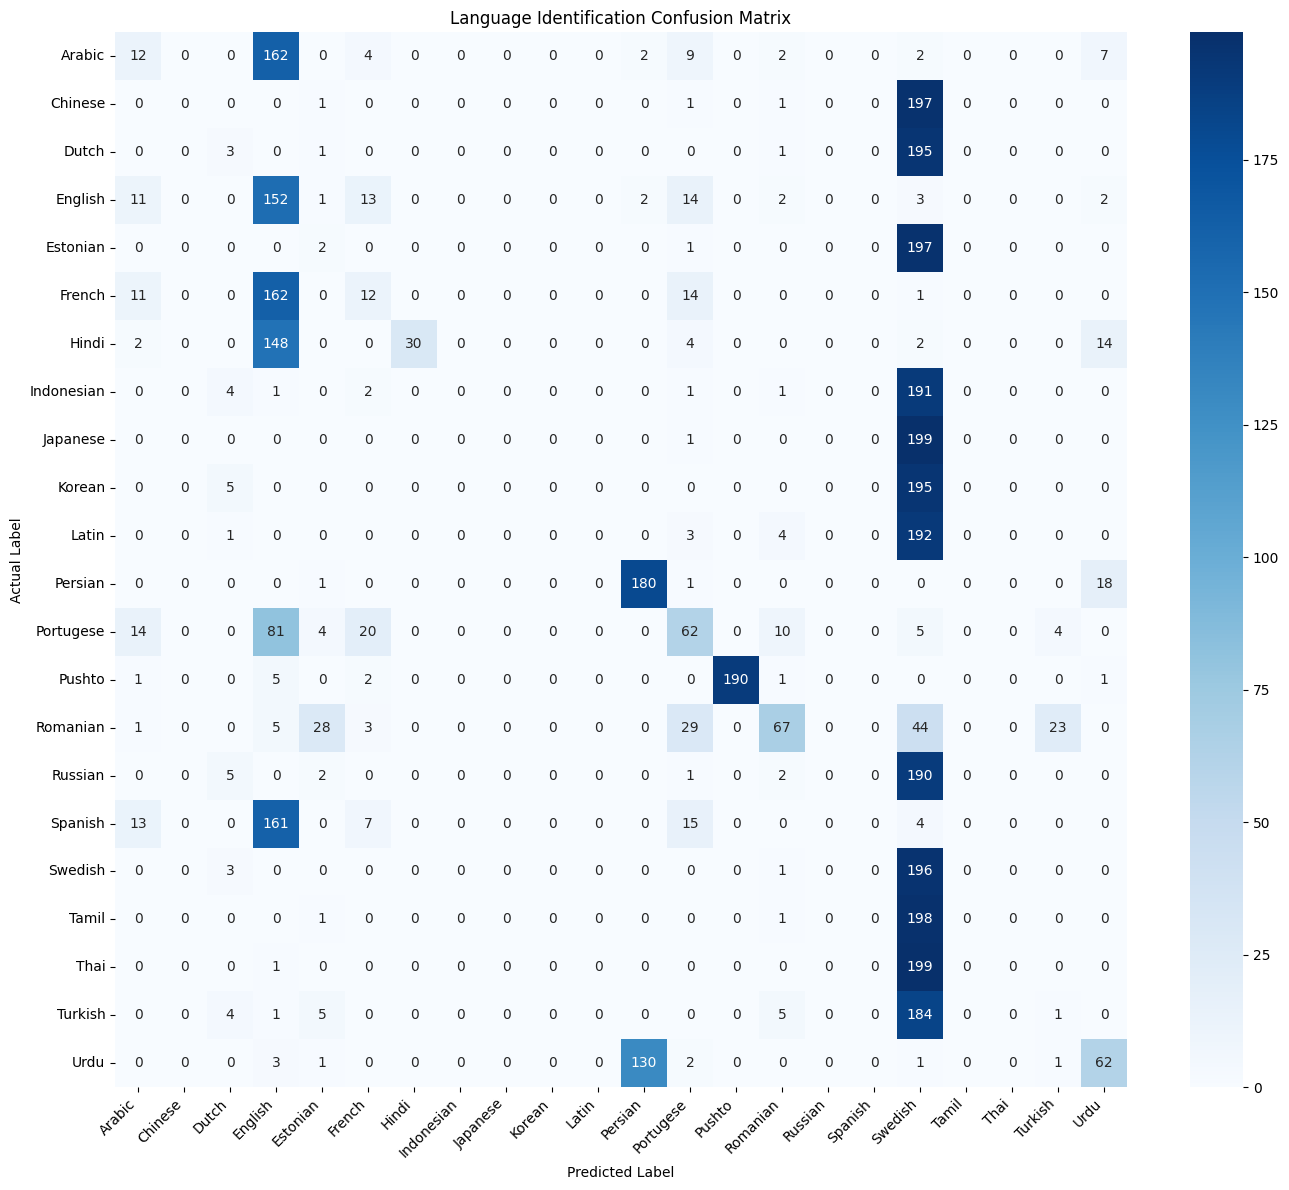

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate predictions
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Print metrics report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Display Confusion Matrix
plt.figure(figsize=(14, 12))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cmap='Blues'
)
plt.title('Language Identification Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [7]:
# Predict on unseen text samples
unseen_samples = [
    "Bonjour, comment allez-vous aujourd'hui?",  # French
    "The quick brown fox jumps over the lazy dog.",  # English
    "Hola, mi nombre es Juan y me encanta programar.",  # Spanish
    "안녕하세요! 오늘 날씨가 참 좋네요.",  # Korean
    "こんにちは、日本食はとても美味しいです。"  # Japanese
]

# Preprocess and tokenise unseen samples
unseen_seq = tokenizer.texts_to_sequences(unseen_samples)
unseen_padded = pad_sequences(unseen_seq, maxlen=max_len, padding='post', truncating='post')

# Make predictions
predictions = model.predict(unseen_padded)
predicted_indices = np.argmax(predictions, axis=1)
predicted_languages = label_encoder.inverse_transform(predicted_indices)

# Show results
print("\nPredictions on Unseen Samples:")
for text, lang in zip(unseen_samples, predicted_languages):
    print(f"Text: '{text}' -> Predicted Language: {lang}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step

Predictions on Unseen Samples:
Text: 'Bonjour, comment allez-vous aujourd'hui?' -> Predicted Language: Swedish
Text: 'The quick brown fox jumps over the lazy dog.' -> Predicted Language: Swedish
Text: 'Hola, mi nombre es Juan y me encanta programar.' -> Predicted Language: Estonian
Text: '안녕하세요! 오늘 날씨가 참 좋네요.' -> Predicted Language: Swedish
Text: 'こんにちは、日本食はとても美味しいです。' -> Predicted Language: Swedish
